# Aula 1 — Séries temporais de sensores e manutenção preditiva

**Do sinal bruto à decisão: que tipo de problema temos nas mãos?**

*Curso de Séries Temporais para Diagnóstico de Falhas: notebook-tutorial autocontido para o Google Colab.*

### O que você vai aprender
1. Por que monitorar a condição de um equipamento (manutenção corretiva, preventiva e preditiva; curva P–F).
2. O que é uma série temporal e por que a **ordem** das amostras importa.
3. Frequência de amostragem, teorema de Nyquist e *aliasing*, com um sinal real.
4. Tendência, sazonalidade e ruído (decomposição STL) e autocorrelação.
5. Conhecer os dois conjuntos do projeto (AI4I 2020 e MetroPT-3) e medir o desbalanceamento.
6. Decidir entre classificação supervisionada e detecção de anomalias.

### Dados usados
- **MHEALTH** (UCI nº 319): 10 voluntários com sensores vestíveis a 50 Hz, 12 atividades físicas (~75 MB).
- **AI4I 2020** (UCI nº 601): 10 000 operações de uma fresadora, com rótulo de falha (~0,5 MB).
- **MetroPT-3** (UCI nº 791): compressor de ar de um trem do Metrô do Porto, uma leitura a cada 10 s, fev.–set. 2020 (~220 MB).

### Como usar este notebook
- No Colab, use **Ambiente de execução → Executar tudo** (ou `Ctrl+F9`). Os dados são baixados
  automaticamente das URLs oficiais na primeira execução e ficam na pasta `/content/dados`.
- As células com título e código recolhido (▸ *Mostrar código*) desenham figuras explicativas.
  Abra o código quando tiver curiosidade; não precisa entendê-lo para seguir o texto.
- Os números citados no texto foram medidos na execução que acompanha este arquivo. Versões
  diferentes das bibliotecas podem mudar a segunda casa decimal, mas não as conclusões.
- Tempo estimado: **1h30 a 2h**. Leitura de apoio: **Capítulo 1** da apostila do curso.

In [ ]:
# @title Configuração: bibliotecas, estilo dos gráficos e download dos dados
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

EM_COLAB = "google.colab" in sys.modules
DADOS = Path(os.environ.get("DADOS_CURSO", "/content/dados" if EM_COLAB else "dados"))
DADOS.mkdir(parents=True, exist_ok=True)
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

# Paleta do curso (a mesma dos slides e da apostila), segura para daltonismo nesta ordem.
AZUL, LARANJA, AQUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAGENTA, VERDE, VIOLETA, VERMELHO = "#e87ba4", "#008300", "#6250d6", "#e34948"
CINZA, CINZA_CLARO, CRITICO = "#898781", "#f0efec", "#d03b3b"
CORES = [AZUL, LARANJA, AQUA, AMARELO, MAGENTA, VERDE, VIOLETA, VERMELHO]

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "axes.prop_cycle": plt.cycler(color=CORES),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlesize": 11, "font.size": 10, "legend.frameon": False, "lines.linewidth": 1.2,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


print(f"Pronto. Os dados baixados ficam na pasta {DADOS}")


Pronto. Os dados baixados ficam na pasta /content/dados


In [ ]:
# @title Leitura do MHEALTH
from series_temporais.connectors import ATIVIDADES, FS_MHEALTH, ler_mhealth


def carregar_mhealth(sujeito: int = 1) -> pd.DataFrame:
    bruto = ler_mhealth(DADOS, sujeito)
    colunas = [*bruto.columns[:12], "atividade_id"]
    df = bruto.loc[bruto["atividade_id"] > 0, colunas].reset_index(drop=True)
    return df.assign(tempo_s=df["amostra"] / FS_MHEALTH, atividade=df["atividade_id"].map(ATIVIDADES))


def trecho(df: pd.DataFrame, atividade: str, coluna: str = "peito_acel_x") -> np.ndarray:
    return df.loc[df["atividade"] == atividade, coluna].to_numpy()


In [ ]:
# @title Leitura do AI4I 2020
from series_temporais.connectors import MODOS_FALHA, ler_ai4i
from series_temporais.preprocessamento import dividir_ai4i


def carregar_ai4i() -> pd.DataFrame:
    return ler_ai4i(DADOS)


In [ ]:
# @title Leitura do MetroPT-3
from series_temporais.connectors import ler_metropt
from series_temporais.preprocessamento import CORTES_METROPT, FALHAS_METROPT, dividir_metropt, rotular_metropt

CORTE_TREINO, CORTE_PUBLICO = CORTES_METROPT


def carregar_metropt() -> pd.DataFrame:
    return rotular_metropt(ler_metropt(DADOS)).reset_index(drop=True)


## 1. Por que olhar sinais de sensores?

Todo equipamento físico se degrada. A questão é **quando** intervir:

| Estratégia | Quando age | Problema |
|---|---|---|
| **Corretiva** | depois que quebra | parada não planejada, dano em cascata, risco |
| **Preventiva** | em intervalos fixos (calendário, horas de uso) | troca peças boas; não evita falhas fora do padrão |
| **Preditiva** | quando um indicador medido mostra degradação | precisa de sensores, dados e modelos, que é o assunto deste curso |

A ideia que sustenta a manutenção preditiva é a **curva P–F**: entre o momento em que uma falha
começa a ser *detectável* (P, falha potencial) e o momento em que o equipamento perde a função (F),
existe um intervalo. Os sinais de sensores (vibração, corrente, pressão, temperatura) mudam
dentro desse intervalo. Quanto mais cedo o modelo percebe a mudança, mais tempo sobra para agir.

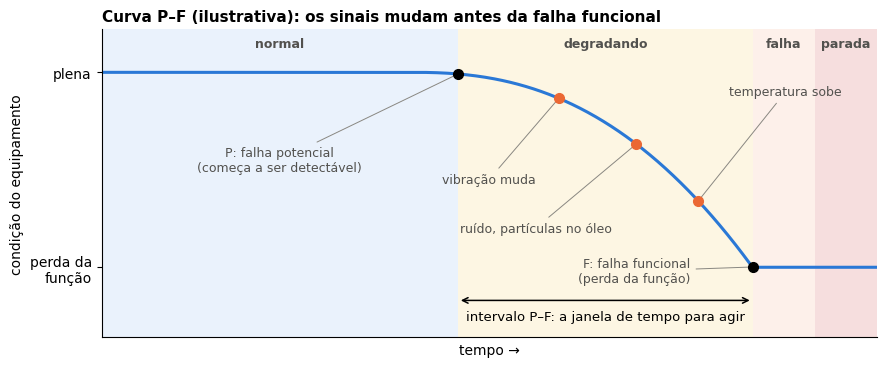

In [ ]:
# @title Figura: a curva P–F
t = np.linspace(0, 10, 500)
tf = 8.4
saude = np.clip(1 - (np.clip(t - 4, 0, None) / (tf - 4)) ** 2.4, 0, 1)
fig, ax = plt.subplots(figsize=(10, 4))
for a, b, nome, cor in [(0, 4.6, "normal", "#eaf2fc"), (4.6, tf, "degradando", "#fdf6e3"),
                        (tf, 9.2, "falha", "#fdf0ea"), (9.2, 10, "parada", "#f6dede")]:
    ax.axvspan(a, b, color=cor, lw=0)
    ax.text((a + b) / 2, 1.13, nome, ha="center", fontsize=9, color="#52514e", weight="bold")
ax.plot(t, saude, color=AZUL, lw=2.2)
marcos = [(4.6, "P: falha potencial\n(começa a ser detectável)", (2.3, 0.55), "center"),
          (5.9, "vibração muda", (5.0, 0.45), "center"),
          (6.9, "ruído, partículas no óleo", (5.6, 0.2), "center"),
          (7.7, "temperatura sobe", (8.1, 0.9), "left"),
          (tf, "F: falha funcional\n(perda da função)", (7.6, -0.02), "right")]
for x, txt, pos, ha in marcos:
    y = float(np.interp(x, t, saude))
    ax.plot(x, y, "o", ms=7, color="black" if txt[:2] in ("P:", "F:") else LARANJA, zorder=5)
    ax.annotate(txt, (x, y), pos, fontsize=9, ha=ha, va="center", color="#52514e",
                arrowprops=dict(arrowstyle="-", color=CINZA, lw=0.7))
ax.annotate("", xy=(tf, -0.17), xytext=(4.6, -0.17), arrowprops=dict(arrowstyle="<->", lw=1.1))
ax.text((4.6 + tf) / 2, -0.27, "intervalo P–F: a janela de tempo para agir", ha="center", fontsize=9.5)
ax.set_ylim(-0.36, 1.22); ax.set_xlim(0, 10); ax.set_xticks([]); ax.grid(False)
ax.set_yticks([0, 1]); ax.set_yticklabels(["perda da\nfunção", "plena"])
ax.set_xlabel("tempo →"); ax.set_ylabel("condição do equipamento")
ax.set_title("Curva P–F (ilustrativa): os sinais mudam antes da falha funcional")
plt.show()

O trabalho de um sistema de diagnóstico é transformar sinais medidos em uma resposta útil, por
exemplo *"esta janela de 10 minutos tem cara de falha?"*, com um número de confiança (o
**score**). Para isso precisamos, antes de tudo, entender o que é um sinal de sensor.

## 2. O que é uma série temporal

Uma **série temporal** é uma sequência de medições indexadas pelo tempo:

$$x_1, x_2, \dots, x_N, \qquad x_n = x(t_n), \quad t_n = n\,\Delta t .$$

- $\Delta t$ é o **intervalo de amostragem** e $f_s = 1/\Delta t$ é a **frequência de amostragem**,
  em hertz (amostras por segundo).
- Um sensor pode medir várias grandezas ao mesmo tempo: a série é então **multivariada**, com
  um vetor $\mathbf{x}_n \in \mathbb{R}^p$ por instante.

O que diferencia uma série temporal de uma tabela comum é que **a ordem carrega informação**.
Vamos ver isso com um sinal real: o acelerômetro no peito de uma pessoa caminhando.

In [ ]:
mh = carregar_mhealth(1)
print(mh.shape)
mh.head()

Baixando mhealth.zip de archive.ics.uci.edu ... 76 MB em 3 s
(35174, 15)


,amostra,peito_acel_x,peito_acel_y,peito_acel_z,ecg_1,ecg_2,tornozelo_acel_x,tornozelo_acel_y,tornozelo_acel_z,tornozelo_giro_x,tornozelo_giro_y,tornozelo_giro_z,atividade_id,tempo_s,atividade
0,6656,-9.7788,0.55690,1.19750,0.008373,-0.033490,2.6493,-9.4517,0.37683,-0.20965,-0.88931,-0.50884,1,133.12,em pé parado
1,6657,-9.7733,0.27880,0.73036,-0.025118,-0.025118,2.4157,-9.5306,0.40179,-0.20965,-0.88931,-0.50884,1,133.14,em pé parado
2,6658,-9.8609,0.11561,0.79988,0.025118,0.016745,2.3865,-9.5991,0.48141,-0.20037,-0.86867,-0.50688,1,133.16,em pé parado
3,6659,-9.7409,0.17652,0.88957,0.180010,0.129770,2.3758,-9.5997,0.42919,-0.20037,-0.86867,-0.50688,1,133.18,em pé parado
4,6660,-9.7821,0.21637,0.90368,0.092098,0.046049,2.3239,-9.5406,0.40038,-0.20037,-0.86867,-0.50688,1,133.20,em pé parado


Cada linha é um instante (50 por segundo). As colunas `peito_acel_*` são o acelerômetro do
peito (m/s²), `ecg_*` as duas derivações do eletrocardiograma (mV) e `tornozelo_*` o acelerômetro
e o giroscópio do tornozelo esquerdo. A coluna `atividade` diz o que a pessoa fazia.

Quanto tempo de cada atividade temos para o voluntário 1?

In [ ]:
duracao = (mh["atividade"].value_counts() / FS_MHEALTH).rename("segundos").to_frame()
duracao["minutos"] = (duracao["segundos"] / 60).round(1)
duracao

,segundos,minutos
atividade,,
agachamento,67.58,1.1
em pé parado,61.44,1.0
deitado,61.44,1.0
sentado,61.44,1.0
caminhando,61.44,1.0
flexão de tronco,61.44,1.0
elevação de braços,61.44,1.0
pedalando,61.44,1.0
trotando,61.44,1.0


### A ordem importa

Na figura abaixo, a linha de cima mostra 10 s de caminhada (500 amostras); a de baixo, **os mesmos
500 valores embaralhados**. À direita, os histogramas: idênticos, porque embaralhar não muda os valores, só a ordem. Média,
desvio padrão, mínimo e máximo também ficam iguais. Mas o ritmo dos passos, que é o que
caracteriza a caminhada, desaparece. Qualquer método que trate as amostras como independentes
(uma tabela comum) joga essa informação fora.

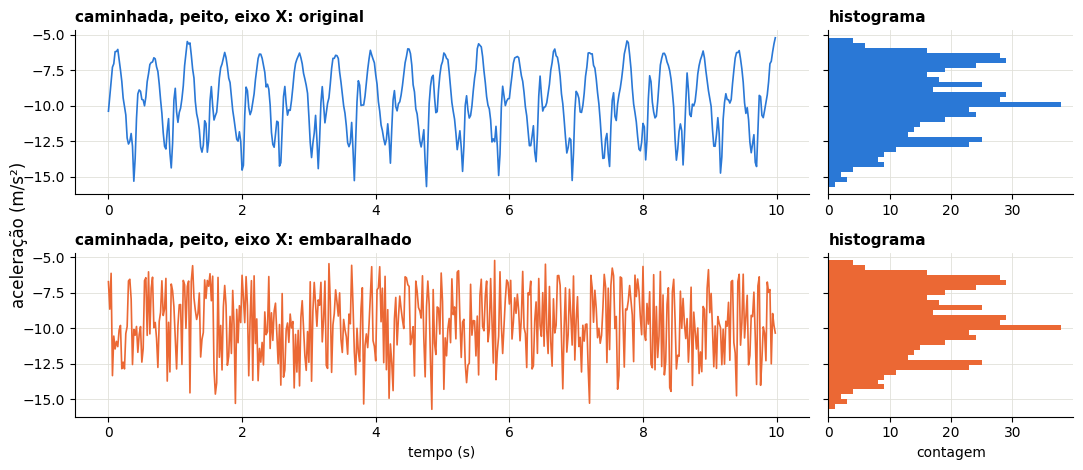

média   — original: -9.681   embaralhado: -9.681
desvio  — original: 2.357   embaralhado: 2.357


In [ ]:
x = trecho(mh, "caminhando")[:500]
embaralhado = rng.permutation(x)
t = np.arange(len(x)) / FS_MHEALTH

fig, eixos = plt.subplots(2, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [3, 1]}, sharey=True)
for linha, (sinal, nome, cor) in enumerate([(x, "original", AZUL), (embaralhado, "embaralhado", LARANJA)]):
    eixos[linha, 0].plot(t, sinal, color=cor)
    eixos[linha, 0].set_title(f"caminhada, peito, eixo X: {nome}")
    eixos[linha, 1].hist(sinal, bins=30, orientation="horizontal", color=cor)
    eixos[linha, 1].set_title("histograma")
eixos[1, 0].set_xlabel("tempo (s)")
eixos[1, 1].set_xlabel("contagem")
fig.supylabel("aceleração (m/s²)")
plt.tight_layout()
plt.show()
print(f"média   — original: {x.mean():.3f}   embaralhado: {embaralhado.mean():.3f}")
print(f"desvio  — original: {x.std():.3f}   embaralhado: {embaralhado.std():.3f}")

## 3. Atividades diferentes, sinais diferentes

Antes de qualquer modelo, **olhe o dado**. Vamos comparar quatro atividades no mesmo eixo do
acelerômetro do peito, com a mesma escala vertical. Repare em três coisas: o **nível médio** do
sinal, a **amplitude** das oscilações e o **ritmo** (quantas oscilações por segundo).

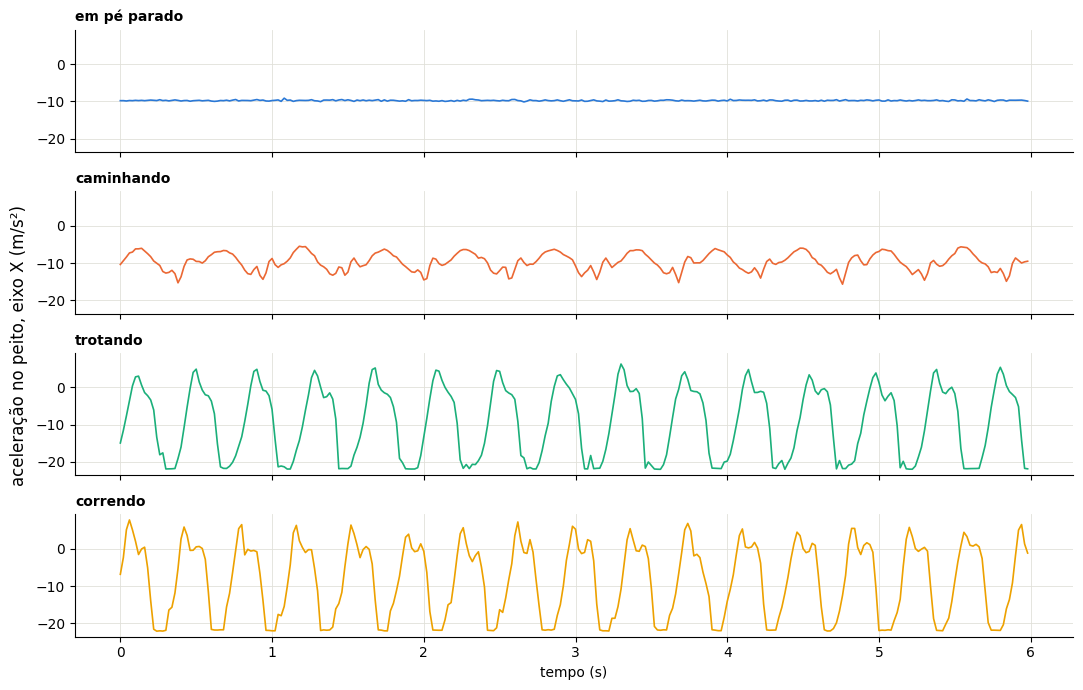

Menor valor registrado na corrida: -22.30 m/s²


In [ ]:
atividades = ["em pé parado", "caminhando", "trotando", "correndo"]
fig, eixos = plt.subplots(len(atividades), 1, figsize=(11, 7), sharex=True, sharey=True)
for eixo, atividade, cor in zip(eixos, atividades, CORES):
    s = trecho(mh, atividade)[:FS_MHEALTH * 6]          # 6 segundos
    eixo.plot(np.arange(len(s)) / FS_MHEALTH, s, color=cor)
    eixo.set_title(atividade, fontsize=10)
eixos[-1].set_xlabel("tempo (s)")
fig.supylabel("aceleração no peito, eixo X (m/s²)")
plt.tight_layout()
plt.show()
print(f"Menor valor registrado na corrida: {trecho(mh, 'correndo').min():.2f} m/s²")

- **Parado**: o sinal fica em torno de −9,8 m/s², quase sem oscilar. O acelerômetro mede também
  a gravidade; o eixo X do peito fica na vertical quando a pessoa está em pé, e o sinal negativo
  vem só da orientação em que o sensor foi preso.
- **Caminhando → trotando**: a amplitude cresce muito e o ritmo acelera. Trote e corrida são
  parecidos em amplitude (os dois saturam, veja abaixo); o ritmo sobe um pouco. Cada ciclo é um passo.
- No trote e na corrida, o sinal **achata** num piso perto de −22 m/s²: o acelerômetro chegou ao
  limite da sua faixa de medição (**saturação**). O que passou desse limite se perdeu, e nenhum
  modelo o recupera. Quando um sinal tem "platôs" perfeitamente retos, desconfie do sensor antes
  de desconfiar do fenômeno.

Essas diferenças de *nível*, *energia* e *ritmo* são exatamente o que, na aula 3, vamos
transformar em números (características) para um modelo usar.

### Um segundo tipo de sinal: o ECG

O peito também tem um eletrocardiograma. Em repouso, vemos o batimento cardíaco com clareza.
Durante a corrida, o sinal fica contaminado pelo movimento: **artefato**, não *"coração
acelerando"*. Sensor real mede o que queremos **e** o que não queremos. Saber separar as duas
coisas é parte do trabalho.

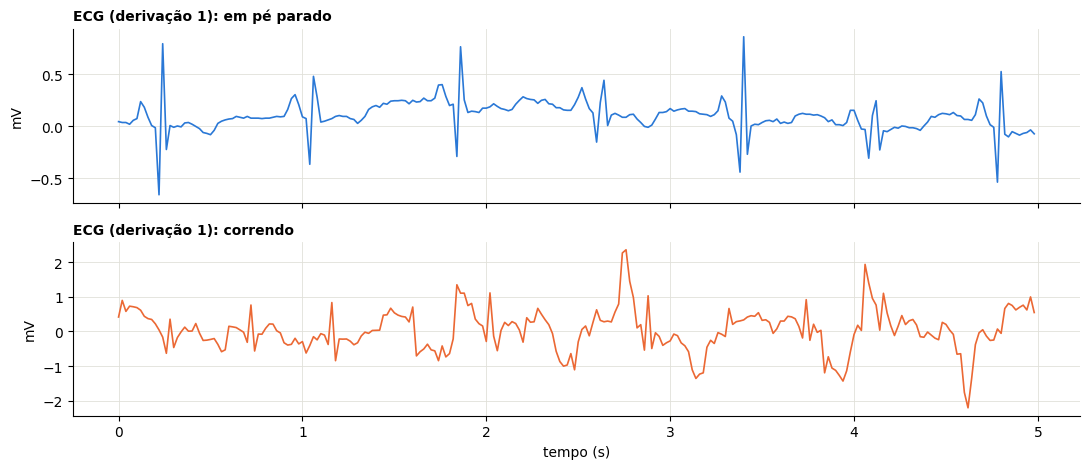

In [ ]:
fig, eixos = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True)
for eixo, atividade, cor in zip(eixos, ["em pé parado", "correndo"], [AZUL, LARANJA]):
    s = trecho(mh, atividade, "ecg_1")[FS_MHEALTH * 5: FS_MHEALTH * 10]
    eixo.plot(np.arange(len(s)) / FS_MHEALTH, s, color=cor)
    eixo.set_title(f"ECG (derivação 1): {atividade}", fontsize=10)
    eixo.set_ylabel("mV")
eixos[-1].set_xlabel("tempo (s)")
plt.tight_layout()
plt.show()

## 4. Amostragem, Nyquist e *aliasing*

Um sensor digital não vê o sinal contínuo, só amostras a cada $\Delta t$. O **teorema de
Nyquist–Shannon** diz que, para representar sem ambiguidade uma componente de frequência $f$, é
preciso amostrar a uma taxa maior que o dobro dela:

$$f_s > 2 f_{\max} \qquad\Longleftrightarrow\qquad f_{\max} < f_N = \frac{f_s}{2}\ \text{(frequência de Nyquist)}.$$

Se o sinal tem energia acima de $f_N$, ela não some: **dobra** para dentro da faixa visível e
aparece como uma frequência falsa. É o *aliasing*. Uma componente de frequência $f$ amostrada a
$f_s$ aparece em $|f - k f_s|$, para o inteiro $k$ que deixa o resultado entre $0$ e $f_N$.

Exemplo sintético: uma senoide de **9 Hz** amostrada a **10 Hz** ($f_N = 5$ Hz). As amostras
caem exatamente sobre uma senoide de $|9 - 10| = 1$ Hz, com a fase invertida.

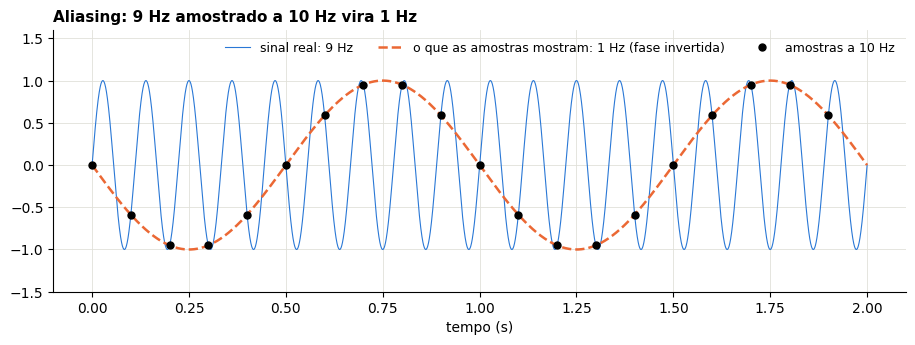

In [ ]:
t_continuo = np.linspace(0, 2, 4000)
t_amostras = np.arange(0, 2, 1 / 10)            # fs = 10 Hz
plt.figure(figsize=(11, 3.4))
plt.plot(t_continuo, np.sin(2 * np.pi * 9 * t_continuo), color=AZUL, lw=0.8, label="sinal real: 9 Hz")
plt.plot(t_continuo, -np.sin(2 * np.pi * 1 * t_continuo), color=LARANJA, lw=1.8, ls="--",
         label="o que as amostras mostram: 1 Hz (fase invertida)")
plt.plot(t_amostras, np.sin(2 * np.pi * 9 * t_amostras), "o", color="black", ms=5, label="amostras a 10 Hz")
plt.xlabel("tempo (s)")
plt.title("Aliasing: 9 Hz amostrado a 10 Hz vira 1 Hz")
plt.legend(loc="upper right", ncols=3, fontsize=9)
plt.ylim(-1.5, 1.6)
plt.show()

### *Aliasing* num sinal real

Agora com a corrida do MHEALTH, gravada a 50 Hz. Vamos reduzir para **5 Hz** de dois jeitos:

1. **Ingênuo**: ficar com uma amostra a cada 10 (`x[::10]`);
2. **Correto**: filtrar as frequências acima da nova $f_N = 2{,}5$ Hz *antes* de descartar
   amostras (`scipy.signal.decimate`, que aplica um filtro passa-baixas antialiasing).

O espectro (que estudaremos na aula 3) mostra quanta energia o sinal tem em cada frequência.

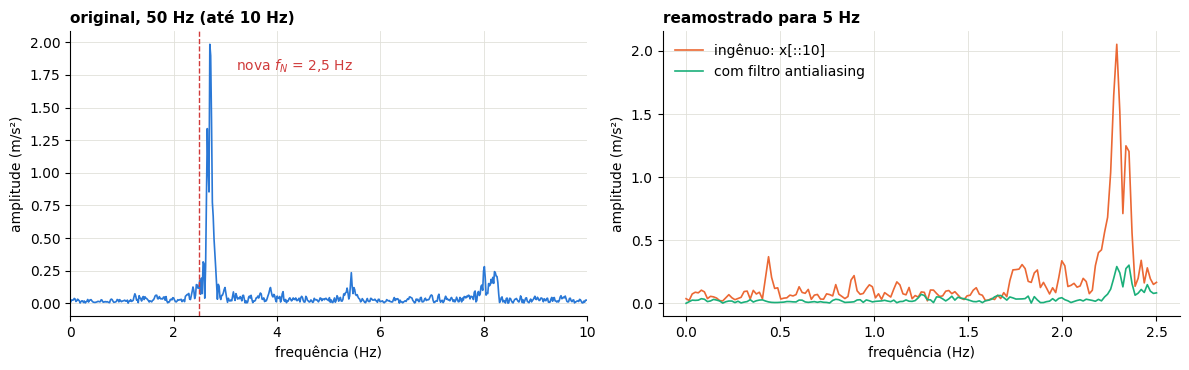

Frequência dominante a 50 Hz: 2.70 Hz (passos por segundo)
Onde ela reaparece a 5 Hz, pela regra |f - k fs|: 2.30 Hz
Onde reaparece o 2º harmônico (5.40 Hz): 0.40 Hz
Fração da potência acima de 2,5 Hz: 99%


In [ ]:
from scipy import signal

corrida = trecho(mh, "correndo")
corrida = corrida - corrida.mean()


def espectro(sinal, fs):
    """Módulo da FFT (metade positiva), com janela de Hann para reduzir o vazamento espectral."""
    janela = np.hanning(len(sinal))
    return np.fft.rfftfreq(len(sinal), 1 / fs), np.abs(np.fft.rfft(sinal * janela)) / len(sinal)


f50, m50 = espectro(corrida, 50)
f_ing, m_ing = espectro(corrida[::10], 5)
f_dec, m_dec = espectro(signal.decimate(corrida, 10, ftype="fir"), 5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(f50, m50, color=AZUL)
ax1.axvline(2.5, color=CRITICO, ls="--", lw=1)
ax1.text(3.2, m50.max() * 0.9, "nova $f_N$ = 2,5 Hz", color=CRITICO)
ax1.set_xlim(0, 10); ax1.set_xlabel("frequência (Hz)"); ax1.set_title("original, 50 Hz (até 10 Hz)")
ax1.set_ylabel("amplitude (m/s²)"); ax2.set_ylabel("amplitude (m/s²)")
ax2.plot(f_ing, m_ing, color=LARANJA, label="ingênuo: x[::10]")
ax2.plot(f_dec, m_dec, color=AQUA, label="com filtro antialiasing")
ax2.set_xlabel("frequência (Hz)"); ax2.set_title("reamostrado para 5 Hz"); ax2.legend()
plt.tight_layout()
plt.show()

pico = f50[np.argmax(m50)]
print(f"Frequência dominante a 50 Hz: {pico:.2f} Hz (passos por segundo)")
print(f"Onde ela reaparece a 5 Hz, pela regra |f - k fs|: {abs(pico - 5):.2f} Hz")
print(f"Onde reaparece o 2º harmônico ({2 * pico:.2f} Hz): {abs(2 * pico - 5):.2f} Hz")
potencia = m50 ** 2
print(f"Fração da potência acima de 2,5 Hz: {potencia[f50 > 2.5].sum() / potencia.sum():.0%}")

O que aconteceu:

- No original, o pico principal está em ~2,7 Hz (o ritmo dos passos), com harmônicos em ~5,4 e
  ~8,1 Hz. **O próprio pico principal já está acima da nova $f_N = 2{,}5$ Hz.**
- Na versão **ingênua**, essa energia não desapareceu: o pico de 2,7 Hz reaparece em
  $|2{,}7 - 5| \approx 2{,}3$ Hz e o harmônico de 5,4 Hz em $|5{,}4 - 5| \approx 0{,}4$ Hz. São
  frequências que **não existem** no movimento. Quem olhasse só o sinal a 5 Hz concluiria que o
  corredor dá 2,3 passos por segundo.
- Com o **filtro antialiasing**, o pico falso em 2,3 Hz cai cerca de 7 vezes, mas não some: o filtro
  do `decimate` corta exatamente em 2,5 Hz, e a sua faixa de transição ainda deixa passar parte dos
  2,7 Hz. Como 99% da potência da corrida está acima de 2,5 Hz (veja a saída), o sinal filtrado fica
  quase vazio. A lição não é que o filtro faz mágica: é que **5 Hz simplesmente não serve** para
  estudar uma corrida, e o filtro pelo menos não deixa você acreditar no contrário.

> **Regra prática.** Antes de reduzir a taxa de amostragem, filtre (ou agregue por média, que é
> um filtro passa-baixas simples, embora imperfeito). E, ao escolher um sensor, garanta $f_s$ bem
> acima do dobro da frequência mais alta que importa para o seu diagnóstico.

## 5. Tendência, sazonalidade e ruído

Muitas séries de equipamentos combinam três componentes:

$$x_t = T_t + S_t + R_t$$

- **Tendência** $T_t$: variação lenta (desgaste, mudança de estação do ano);
- **Sazonalidade** $S_t$: padrão que se repete com período conhecido (o ciclo diário de operação);
- **Resíduo** $R_t$: o que sobra. É nele que costumam aparecer as anomalias.

Vamos decompor a temperatura do óleo do compressor do MetroPT-3, agregada por hora, com a
**STL** (*Seasonal-Trend decomposition using Loess*), usando período de 24 horas. O carregamento
completo do MetroPT-3 leva alguns segundos (são 1,5 milhão de linhas).

In [ ]:
metro = carregar_metropt()
print(metro.shape)
print("de", metro["timestamp"].min(), "a", metro["timestamp"].max())
metro.head()

Baixando metropt3.zip de archive.ics.uci.edu ... 218 MB em 6 s
(1516948, 17)
de 2020-02-01 00:00:00 a 2020-09-01 03:59:50


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses,falha
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0


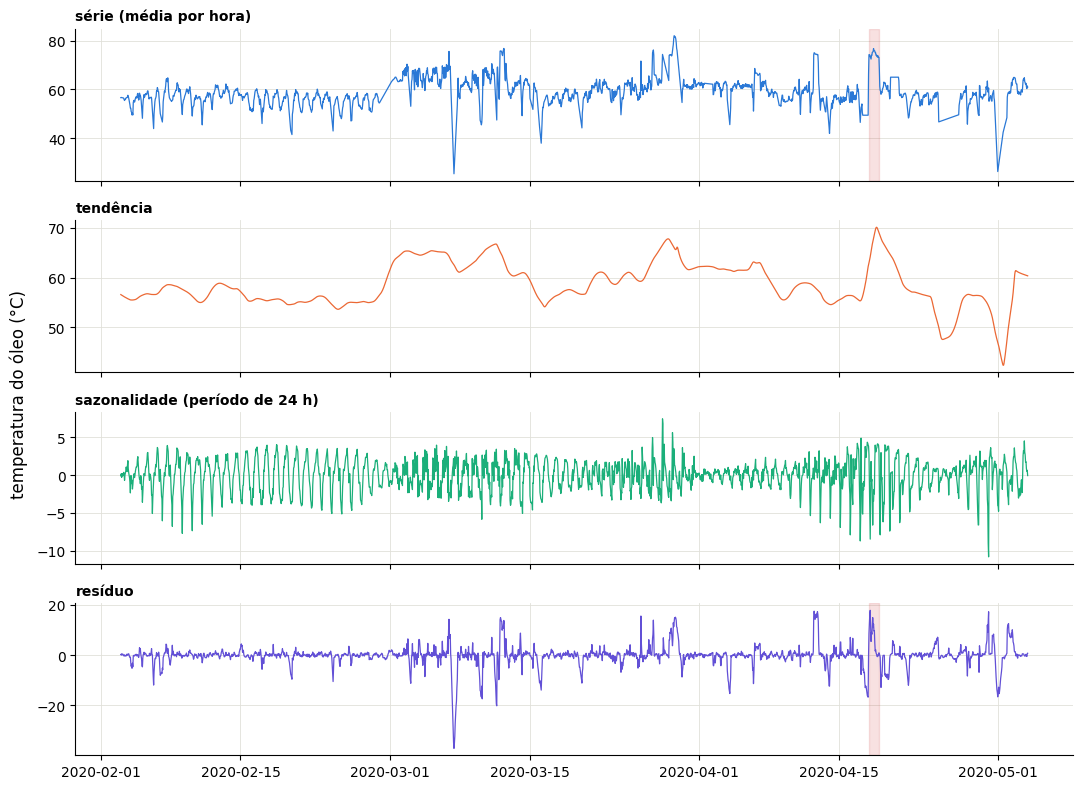

In [ ]:
from statsmodels.tsa.seasonal import STL

oleo_hora = metro.set_index("timestamp")["Oil_temperature"].resample("1h").mean()
oleo_hora = oleo_hora["2020-02-03":"2020-05-03"].interpolate()
decomposicao = STL(oleo_hora, period=24, robust=True).fit()

fig, eixos = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
partes = [(oleo_hora, "série (média por hora)", AZUL), (decomposicao.trend, "tendência", LARANJA),
          (decomposicao.seasonal, "sazonalidade (período de 24 h)", AQUA), (decomposicao.resid, "resíduo", VIOLETA)]
for eixo, (serie, nome, cor) in zip(eixos, partes):
    eixo.plot(serie.index, serie.values, color=cor, lw=0.9)
    eixo.set_title(nome, fontsize=10)
eixos[0].axvspan(pd.Timestamp("2020-04-18"), pd.Timestamp("2020-04-19"), color=CRITICO, alpha=0.15)
eixos[3].axvspan(pd.Timestamp("2020-04-18"), pd.Timestamp("2020-04-19"), color=CRITICO, alpha=0.15)
fig.supylabel("temperatura do óleo (°C)")
plt.tight_layout()
plt.show()

A faixa vermelha marca o primeiro evento de falha documentado (18 de abril). Repare:

- A **tendência** não é constante: fica em ~55 °C em fevereiro, muda de patamar em março (logo
  depois de um buraco de 28 horas nos dados) e oscila por semanas. Um limiar fixo de temperatura
  ajustado em fevereiro dispararia em março sem que nada estivesse errado.
- A **sazonalidade** diária reflete a rotina de operação do trem (horários de pico, madrugada parada).
- No dia da falha, a temperatura sobe a ~75 °C: com o vazamento, o compressor trabalha mais. A STL
  divide essa subida entre a tendência e o resíduo. Mas o **resíduo** tem picos do mesmo tamanho em
  março, sem falha nenhuma: um alarme baseado só na temperatura média por hora dispararia muitas
  vezes à toa. Precisaremos de mais sensores (pressões, corrente) e de janelas mais curtas.
- Os trechos perfeitamente retos não são o compressor: são buracos sem dados que a interpolação
  preencheu com retas (o maior, de 48 h, em 25–27 de abril). Cerca de 14% das horas dessa janela não
  têm dado, e isso também deforma a tendência no fim de abril. A aula 2 trata desses buracos.

## 6. Autocorrelação: a série se parece com ela mesma deslocada?

A **função de autocorrelação** (ACF) mede a correlação entre a série e uma cópia dela atrasada
de $h$ amostras (o *lag*):

$$\rho(h) = \frac{\sum_{t=1}^{N-h} (x_t - \bar x)(x_{t+h} - \bar x)}{\sum_{t=1}^{N} (x_t - \bar x)^2}.$$

- $\rho(0) = 1$ sempre;
- picos em $h = P$ indicam **periodicidade** de período $P$ amostras;
- para ruído branco, $\rho(h) \approx 0$, dentro da faixa $\pm 1{,}96/\sqrt{N}$ (95%).

Vamos comparar a caminhada original com a versão embaralhada da seção 2.

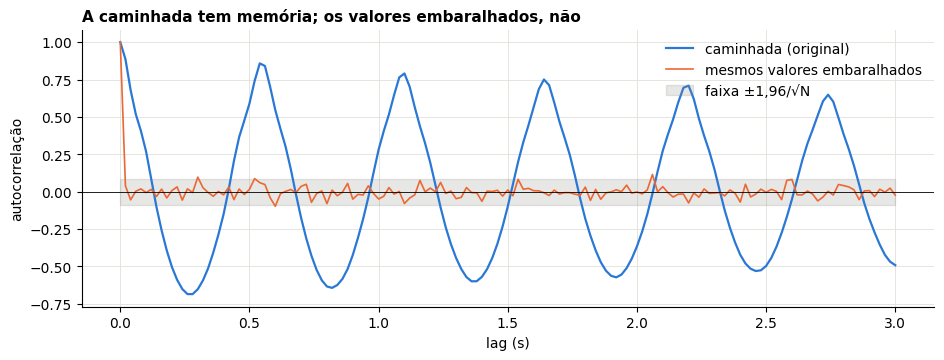

Primeiro pico forte da ACF em 0.54 s: o período de um passo


In [ ]:
from statsmodels.tsa.stattools import acf

lags = 150                                      # 3 segundos
acf_original = acf(x, nlags=lags, fft=True)
acf_embaralhado = acf(embaralhado, nlags=lags, fft=True)
banda = 1.96 / np.sqrt(len(x))
tempo_lag = np.arange(lags + 1) / FS_MHEALTH

plt.figure(figsize=(11, 3.6))
plt.plot(tempo_lag, acf_original, color=AZUL, lw=1.6, label="caminhada (original)")
plt.plot(tempo_lag, acf_embaralhado, color=LARANJA, lw=1.2, label="mesmos valores embaralhados")
plt.fill_between(tempo_lag, -banda, banda, color=CINZA, alpha=0.2, label="faixa ±1,96/√N")
plt.axhline(0, color="black", lw=0.6)
plt.xlabel("lag (s)"); plt.ylabel("autocorrelação")
plt.title("A caminhada tem memória; os valores embaralhados, não")
plt.legend()
plt.show()

from scipy.signal import find_peaks

picos, _ = find_peaks(acf_original, height=0.3)
pico_lag = picos[0]
print(f"Primeiro pico forte da ACF em {pico_lag / FS_MHEALTH:.2f} s: o período de um passo")

A ACF da caminhada oscila com picos regulares, a cada ~0,55 s: o período de um passo (o peito
sobe e desce uma vez por passo, ~110 passos por minuto). A correlação continua alta mesmo depois
de vários passos. A versão embaralhada fica praticamente dentro da faixa de ruído (com 95% de
confiança, espera-se que ~1 lag em 20 escape dela por acaso). A autocorrelação é a razão de existir das técnicas deste curso: **amostras
vizinhas não são independentes**. Isso tem uma consequência séria, que vamos explorar na aula 5:
dividir uma série em treino e teste **sorteando** amostras deixa o teste quase igual ao treino e
infla a métrica.

## 7. O conjunto da trilha fácil: AI4I 2020

O AI4I 2020 é um conjunto **sintético** que reproduz dados de manutenção de uma fresadora. Cada
linha é uma operação, com o tipo do produto (`Type`: L, M ou H, de qualidade baixa, média e alta),
cinco medições e o rótulo `Machine failure`.

In [ ]:
ai4i = carregar_ai4i()
print(ai4i.shape)
ai4i.info()

Baixando ai4i2020.zip de archive.ics.uci.edu ... 1 MB em 1 s
(10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF 

In [ ]:
ai4i.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Quantas falhas?

Primeira coisa a medir em qualquer problema de diagnóstico: a **prevalência**, a fração de
exemplos positivos.

In [ ]:
taxa = ai4i["Machine failure"].mean()
print(f"Falhas: {ai4i['Machine failure'].sum()} de {len(ai4i)} operações ({taxa:.2%})")
print(f"Um 'modelo' que SEMPRE diz 'normal' acerta {1 - taxa:.2%} das vezes, sem detectar nenhuma falha.")

Falhas: 339 de 10000 operações (3.39%)
Um 'modelo' que SEMPRE diz 'normal' acerta 96.61% das vezes, sem detectar nenhuma falha.


Esse é o **paradoxo da acurácia**: com 3,4% de falhas, 96,6% de acerto não diz nada. Por isso o
curso usa métricas como a **PR-AUC** (área sob a curva precisão–revocação), que só fica alta se o
modelo encontrar as falhas *e* não disparar alarmes demais (aula 5).

### Os modos de falha

As colunas `TWF`, `HDF`, `PWF`, `OSF` e `RNF` dizem **por que** a máquina falhou: desgaste da
ferramenta, dissipação de calor, potência, sobrecarga e falha aleatória. Elas **não podem** ser
usadas como entrada de um modelo, porque só existem *depois* da falha: seria entregar a resposta
(vazamento de rótulo).

In [ ]:
falhas = ai4i[ai4i["Machine failure"] == 1]
modos = pd.DataFrame({"entre as falhas": falhas[MODOS_FALHA].sum(),
                      "em operações SEM falha": ai4i.loc[ai4i["Machine failure"] == 0, MODOS_FALHA].sum()})
modos["descrição"] = ["desgaste da ferramenta", "dissipação de calor", "potência",
                      "sobrecarga", "aleatória"]
display(modos)
print("Falhas com mais de um modo:", int((falhas[MODOS_FALHA].sum(axis=1) > 1).sum()))
print("Falhas sem nenhum modo marcado:", int((falhas[MODOS_FALHA].sum(axis=1) == 0).sum()))

,entre as falhas,em operações SEM falha,descrição
TWF,46,0,desgaste da ferramenta
HDF,115,0,dissipação de calor
PWF,95,0,potência
OSF,98,0,sobrecarga
RNF,1,18,aleatória


Falhas com mais de um modo: 24
Falhas sem nenhum modo marcado: 9


Repare no modo aleatório (`RNF`): quase todas as suas marcações estão em operações **sem** falha.
É uma inconsistência conhecida deste conjunto, e mais um motivo para nunca usar essas colunas. Na
prática, as falhas vêm de quatro modos (HDF, OSF, PWF e TWF), e o desgaste da ferramenta tem poucos
exemplos.

### Uma variável separa as classes?

Vamos comparar a distribuição do torque nas operações normais e nas falhas.

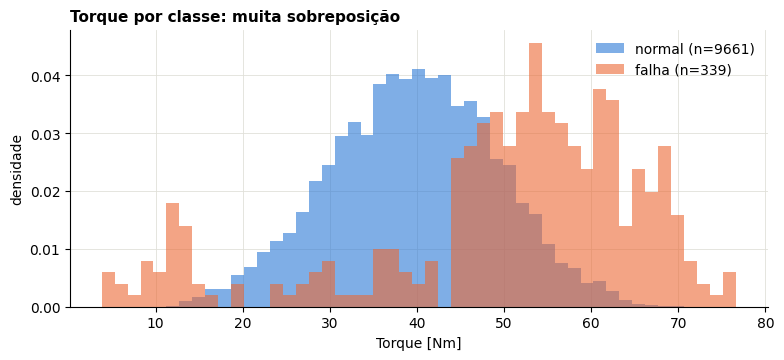

In [ ]:
coluna = "Torque [Nm]"
normal = ai4i.loc[ai4i["Machine failure"] == 0, coluna]
falha = ai4i.loc[ai4i["Machine failure"] == 1, coluna]

bins = np.linspace(ai4i[coluna].min(), ai4i[coluna].max(), 50)   # as mesmas caixas para as duas classes
plt.figure(figsize=(9, 3.6))
plt.hist(normal, bins=bins, density=True, alpha=0.6, color=AZUL, label=f"normal (n={len(normal)})")
plt.hist(falha, bins=bins, density=True, alpha=0.6, color=LARANJA, label=f"falha (n={len(falha)})")
plt.xlabel(coluna); plt.ylabel("densidade")
plt.title("Torque por classe: muita sobreposição")
plt.legend()
plt.show()

As falhas se concentram sobretudo no torque alto (acima de ~45 Nm), com um grupo menor em torque
muito baixo (5–15 Nm), mas a sobreposição é grande: um limiar sozinho
não resolve. Combinando **duas** variáveis, a estrutura aparece:

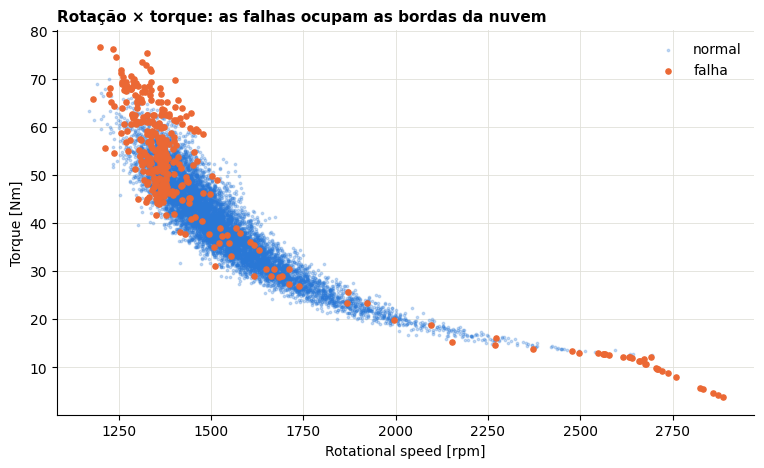

In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(ai4i.loc[normal.index, "Rotational speed [rpm]"], normal, s=3, alpha=0.25, color=AZUL, label="normal")
plt.scatter(ai4i.loc[falha.index, "Rotational speed [rpm]"], falha, s=14, color=LARANJA, label="falha")
plt.xlabel("Rotational speed [rpm]"); plt.ylabel("Torque [Nm]")
plt.title("Rotação × torque: as falhas ocupam as bordas da nuvem")
plt.legend()
plt.show()

Torque e rotação variam em sentidos **opostos**: a máquina opera com potência mecânica
($P = \tau\,\omega$) mais ou menos estável, e a nuvem desenha uma hipérbole. As falhas se
concentram nas **pontas** da nuvem: torque alto com rotação baixa (canto superior esquerdo:
sobrecarga e potência alta demais) e rotação alta com torque baixo (canto inferior direito:
potência baixa demais). As falhas no meio da nuvem dependem de outras variáveis, como o desgaste
da ferramenta e a diferença entre as temperaturas. Um classificador que combina variáveis
consegue aprender essas regiões, como veremos na aula 4.

> **Atenção, armadilha.** A coluna `UDI` é só um identificador sequencial. O curso a usa como
> **ordem do tempo** (as operações aconteceram nessa sequência). Ela nunca deve entrar como
> característica do modelo.

## 8. O conjunto da trilha difícil: MetroPT-3

Agora um sinal industrial de verdade: a unidade de produção de ar comprimido de um trem do
Metrô do Porto. Sete sensores analógicos e oito digitais, uma leitura a cada ~10 segundos.

| Sensor | O que mede |
|---|---|
| `TP2`, `TP3` | pressão no compressor e no painel pneumático (bar) |
| `H1` | pressão na válvula de descarga do filtro ciclônico (bar) |
| `DV_pressure` | queda de pressão na descarga dos secadores (bar) |
| `Reservoirs` | pressão nos reservatórios de ar (bar) |
| `Oil_temperature` | temperatura do óleo do compressor (°C) |
| `Motor_current` | corrente do motor (A) |
| `COMP`, `DV_eletric`, `Towers`, `MPG`, `LPS`, `Pressure_switch`, `Oil_level`, `Caudal_impulses` | sinais digitais (0/1) de válvulas, chaves e controle |

### A amostragem é mesmo regular?

In [ ]:
dt = metro["timestamp"].diff().dt.total_seconds()
print("Intervalo mais comum entre leituras:", dt.mode().iloc[0], "s")
print(dt.describe().round(1))
buracos = metro.loc[dt > 60, "timestamp"]
print(f"\nIntervalos maiores que 1 minuto: {len(buracos)}")
maiores = dt.nlargest(5)
for i, segundos in maiores.items():
    print(f"  {metro['timestamp'].iloc[i - 1]} -> {metro['timestamp'].iloc[i]}: {segundos / 3600:.1f} h sem dados")

Intervalo mais comum entre leituras: 10.0 s
count    1516947.0
mean          12.1
std          314.1
min            8.0
25%           10.0
50%           10.0
75%           10.0
max       172918.0
Name: timestamp, dtype: float64

Intervalos maiores que 1 minuto: 331
  2020-04-25 01:10:51 -> 2020-04-27 01:12:49: 48.0 h sem dados
  2020-06-27 10:53:07 -> 2020-06-28 23:07:43: 36.2 h sem dados
  2020-02-28 23:57:08 -> 2020-03-01 04:00:09: 28.1 h sem dados
  2020-08-04 07:42:28 -> 2020-08-05 08:23:01: 24.7 h sem dados
  2020-05-24 00:39:23 -> 2020-05-25 01:14:14: 24.6 h sem dados


Quase todas as leituras vêm a cada ~10 s, mas há **buracos**: horas ou dias sem dados (sistema
desligado, falha de comunicação). Em uma série real, o eixo do tempo também precisa ser
inspecionado. A aula 2 trata desses buracos.

### Duas horas de operação

Vamos olhar quatro sinais na manhã de 2 de março de 2020: a pressão na saída do compressor (`TP2`),
a pressão nos reservatórios (`Reservoirs`), a corrente do motor e a temperatura do óleo.

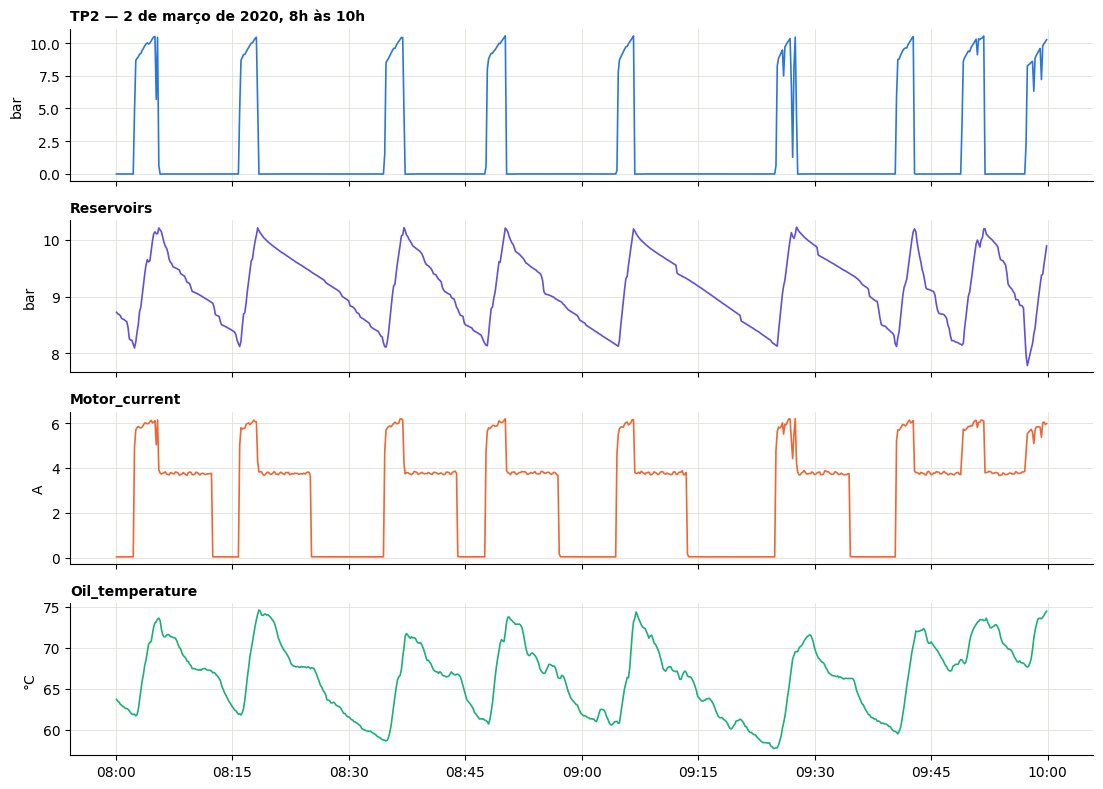

In [ ]:
duas_horas = metro[(metro["timestamp"] >= "2020-03-02 08:00") & (metro["timestamp"] < "2020-03-02 10:00")]
import matplotlib.dates as mdates

fig, eixos = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for eixo, coluna, cor, unidade in zip(eixos, ["TP2", "Reservoirs", "Motor_current", "Oil_temperature"],
                                      [AZUL, VIOLETA, LARANJA, AQUA], ["bar", "bar", "A", "°C"]):
    eixo.plot(duas_horas["timestamp"], duas_horas[coluna], color=cor)
    eixo.set_title(coluna, fontsize=10)
    eixo.set_ylabel(unidade)
eixos[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
eixos[0].set_title("TP2 — 2 de março de 2020, 8h às 10h", fontsize=10)
plt.tight_layout()
plt.show()

O compressor alterna três estados:

- **em carga**: o motor puxa ~6 A, `TP2` sobe de ~8,5 para ~10,5 bar e enche os reservatórios;
- **em alívio**: o motor continua girando (~3,8 A), mas a saída é despressurizada (`TP2` ≈ 0);
- **desligado**: corrente 0, enquanto o trem consome o ar e a pressão dos reservatórios cai devagar.

Cada ciclo dura ~13–15 minutos, e o óleo esquenta ~12 °C a cada fase de carga. Esse ritmo é o
"normal" do compressor; um vazamento de ar o altera (o compressor precisa trabalhar mais), e é isso
que um modelo vai tentar perceber.

### Onde estão as falhas?

O CSV **não tem rótulo**. A empresa documentou quatro intervalos de falha (todos **vazamento de
ar**), e o leitor deste notebook (`carregar_metropt`) marca com `falha = 1` as leituras dentro
deles. Vamos ver os eventos sobre a série inteira, junto com os cortes da divisão oficial do curso
(treino, teste público, teste privado).

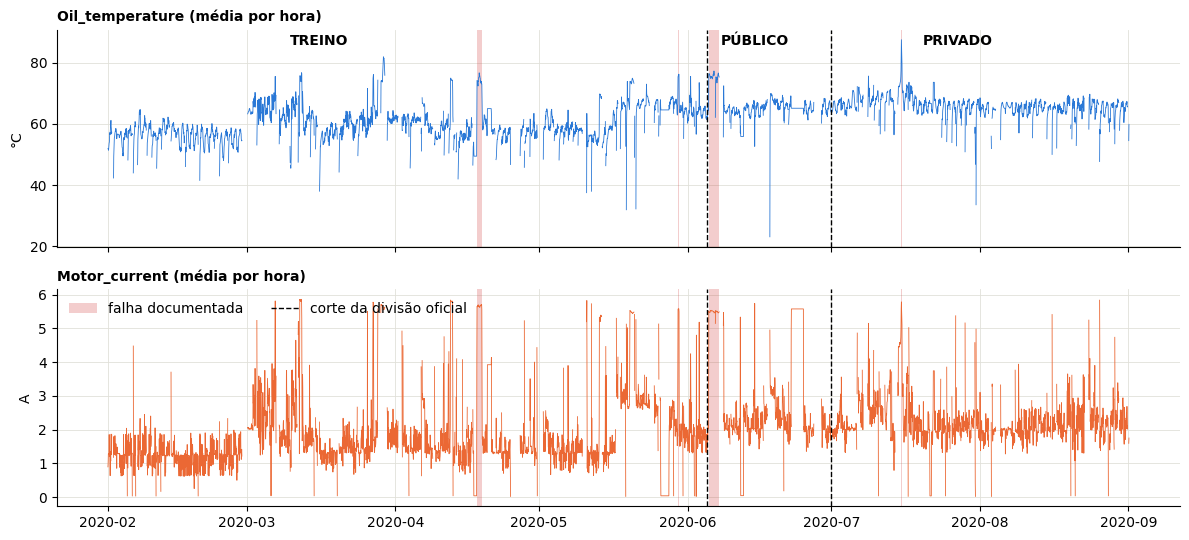

Leituras em falha no total: 1.97%
  treino        :   887,178 leituras, 1.24% em falha
  teste público :   186,168 leituras, 9.30% em falha
  teste privado :   443,602 leituras, 0.37% em falha


In [ ]:
por_hora = metro.set_index("timestamp")[["Oil_temperature", "Motor_current", "falha"]].resample("1h").mean()

fig, eixos = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for eixo, coluna, cor in zip(eixos, ["Oil_temperature", "Motor_current"], [AZUL, LARANJA]):
    eixo.plot(por_hora.index, por_hora[coluna], color=cor, lw=0.6)
    eixo.set_title(f"{coluna} (média por hora)", fontsize=10)
    for k, (inicio, fim) in enumerate(FALHAS_METROPT):
        eixo.axvspan(pd.Timestamp(inicio), pd.Timestamp(fim), color=CRITICO, alpha=0.25, lw=0,
                     label="falha documentada" if k == 0 else None)
    for k, corte in enumerate((CORTE_TREINO, CORTE_PUBLICO)):
        eixo.axvline(corte, color="black", ls="--", lw=1, label="corte da divisão oficial" if k == 0 else None)
eixos[0].set_ylabel("°C"); eixos[1].set_ylabel("A")
eixos[1].legend(loc="upper left", ncols=2)
eixos[0].text(pd.Timestamp("2020-03-10"), por_hora["Oil_temperature"].max() * 0.98, "TREINO", weight="bold")
eixos[0].text(pd.Timestamp("2020-06-08"), por_hora["Oil_temperature"].max() * 0.98, "PÚBLICO", weight="bold")
eixos[0].text(pd.Timestamp("2020-07-20"), por_hora["Oil_temperature"].max() * 0.98, "PRIVADO", weight="bold")
plt.tight_layout()
plt.show()

treino_m, publico_m, privado_m = dividir_metropt(metro)
print(f"Leituras em falha no total: {metro['falha'].mean():.2%}")
for nome, parte in [("treino", treino_m), ("teste público", publico_m), ("teste privado", privado_m)]:
    print(f"  {nome:14s}: {len(parte):>9,} leituras, {parte['falha'].mean():.2%} em falha")

Observe:

- A prevalência muda muito de um conjunto para outro: cerca de 1% no treino, 9% no teste
  público (que contém o evento mais longo, de 5 a 7 de junho) e menos de 0,5% no privado. Uma
  métrica que dependa da prevalência (como a PR-AUC) **não é comparável** entre esses conjuntos.
- O evento de julho só existe no teste privado. O modelo será julgado numa falha que nunca viu,
  em pleno verão, com o equipamento em outra condição térmica. É um teste exigente e honesto.
  (Os eventos de maio e julho duram poucas horas e quase não aparecem nesta escala.)

## 9. Supervisionado ou detecção de anomalias?

Com o dado conhecido, a pergunta de projeto é: **que tipo de modelo cabe aqui?**

| | **Classificação supervisionada** | **Detecção de anomalias** |
|---|---|---|
| Aprende com | exemplos rotulados de normal **e** de falha | só exemplos normais |
| Pergunta | "isto se parece com as falhas que já vi?" | "isto foge do normal que conheço?" |
| Ponto forte | muito preciso para falhas conhecidas e bem representadas | detecta falhas **novas**, nunca vistas |
| Ponto fraco | não reconhece um tipo de falha ausente do treino | alarma qualquer coisa incomum, inclusive o que não é falha |
| Quando usar | muitas falhas rotuladas e de poucos tipos | falhas raras, caras de rotular ou imprevisíveis |

Aplicado aos nossos dados:

- **AI4I**: 339 falhas rotuladas, quase todas de quatro modos conhecidos (HDF, OSF, PWF, TWF). Um
  classificador supervisionado é a escolha natural; um detector de anomalias serve de comparação.
- **MetroPT-3**: só **dois** eventos de falha no treino, ambos do mesmo tipo, e ~880 mil
  leituras normais. Aprender "o normal" e alarmar o que foge dele é uma estratégia forte; um
  classificador terá pouquíssimos exemplos positivos para aprender.

No curso você vai testar **as duas** abordagens e deixar os números decidirem (aula 4).

## 10. Exercícios

1. **Outras atividades.** Refaça o gráfico da seção 3 com `"subindo escada"`, `"pedalando"` e
   `"saltando"`. Qual delas tem o ritmo mais rápido? E o nível médio mais afastado de −9,8 m/s²?
2. **Outro eixo.** Redefina `x = trecho(mh, "caminhando", "tornozelo_acel_x")[:500]` e
   `embaralhado = rng.permutation(x)` e rode de novo a célula da seção 6. O período no tornozelo é o
   mesmo do peito? Por quê? *Dica: o tornozelo esquerdo só "pisa" uma vez a cada dois passos.*
3. **Aliasing.** Repita a seção 4 reduzindo para 10 Hz: `espectro(corrida[::5], 10)` e
   `espectro(signal.decimate(corrida, 5, ftype="fir"), 10)`. O pico de 2,7 Hz sobrevive? E os
   harmônicos de 5,4 e 8,1 Hz, para onde dobram? Explique com a frequência de Nyquist.
4. **STL na corrente.** Decomponha `Motor_current` (média por hora) do MetroPT-3 com a STL. A
   sazonalidade diária é parecida com a da temperatura?
5. **Seu diagnóstico.** Escreva um parágrafo escolhendo uma trilha (AI4I ou MetroPT-3) que diga:
   a prevalência de falhas, quantos eventos ou exemplos de falha existem no treino, se você começaria
   por um classificador supervisionado ou por um detector de anomalias, e por quê, **com os números
   medidos aqui**.

## Resumo

- Manutenção preditiva explora o intervalo P–F: os sinais mudam antes da falha funcional.
- Série temporal = medições ordenadas no tempo; **a ordem carrega informação** (ritmo,
  autocorrelação) que métodos de tabela ignoram.
- $f_s$ precisa ser maior que o dobro da frequência mais alta de interesse; reduzir a amostragem
  sem filtrar cria **aliasing**.
- STL separa tendência, sazonalidade e resíduo; a tendência muda de patamar ao longo das semanas, e
  isso já engana limiares fixos.
- AI4I: 3,4% de falhas, quatro modos relevantes. MetroPT-3: quatro eventos de vazamento de ar,
  prevalência que varia de ~0,4% a ~9% entre os conjuntos. **Acurácia não serve** para nenhum dos dois.

## Referências

- BANOS, O. et al. mHealthDroid: a novel framework for agile development of mobile health applications. *IWAAL*, 2014. Dados: MHEALTH, UCI Machine Learning Repository, doi:10.24432/C5TW22.
- MATZKA, S. Explainable artificial intelligence for predictive maintenance applications. *AI4I*, 2020. Dados: AI4I 2020, UCI, doi:10.24432/C5HS5C.
- DAVARI, N. et al. Predictive maintenance based on anomaly detection using deep learning for air production unit in the railway industry. *IEEE DSAA*, 2021. Dados: MetroPT-3, UCI, doi:10.24432/C5VW3R.
- CLEVELAND, R. B. et al. STL: a seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics*, v. 6, n. 1, p. 3–73, 1990.
- HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: principles and practice*. 3. ed. OTexts, 2021. Disponível em: https://otexts.com/fpp3/.
- MOUBRAY, J. *Reliability-centered maintenance*. 2. ed. Industrial Press, 1997 (curva P–F).

## 11. Dados preparados para machine learning

A especificação está em [specs/001-pipeline.md](specs/001-pipeline.md). Execute `python -m series_temporais.pipeline` na raiz do projeto para gerar os CSVs. A célula abaixo apresenta as primeiras linhas, o balanceamento de classes e as estatísticas por partição.

In [ ]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

for base in ("mhealth", "ai4i", "metropt"):
    pasta = Path("resultados") / base
    display(Markdown(f"### {base.upper()}"))
    if not (pasta / "previa.csv").is_file():
        print(f"Gere os resultados com: python -m series_temporais.pipeline --base {base}")
        continue
    resumo = json.loads((pasta / "resumo.json").read_text(encoding="utf-8"))
    preditores = resumo["preditores"]
    print(f'{resumo["linhas"]:,} exemplos e {len(preditores)} preditores')
    previa = pd.read_csv(pasta / "previa.csv")
    metadados = [coluna for coluna in previa if coluna not in preditores]
    display(previa[metadados + preditores[:4]].head())
    print("A tabela completa e as demais características estão nos CSVs.")
    display(pd.read_csv(pasta / "classes.csv"))
    estatisticas = pd.read_csv(pasta / "estatisticas.csv")
    display(estatisticas.groupby("particao", sort=False).head(5))


### MHEALTH

5,223 exemplos e 182 preditores


,particao,sujeito,amostra_inicio,amostra_fim,alvo,peito_acel_x__media,peito_acel_x__desvio,peito_acel_x__min,peito_acel_x__max
0,treino,1,6656,6783,1,-9.727627,0.139661,-10.039,-9.1065
1,treino,1,6720,6847,1,-9.749610,0.143924,-10.117,-9.3725
2,treino,1,6784,6911,1,-9.751380,0.131724,-10.117,-9.3982
3,treino,1,6848,6975,1,-9.733466,0.125877,-10.006,-9.3312
4,treino,1,6912,7039,1,-9.746206,0.125533,-10.012,-9.3312


A tabela completa e as demais características estão nos CSVs.


,particao,classe,exemplos,percentual,atividade
0,treino,1,329,8.937789,em pé parado
1,treino,2,329,8.937789,sentado
2,treino,3,329,8.937789,deitado
3,treino,4,329,8.937789,caminhando
4,treino,5,324,8.801956,subindo escada
5,treino,6,317,8.611790,flexão de tronco
6,treino,7,315,8.557457,elevação de braços
7,treino,8,317,8.611790,agachamento
8,treino,9,329,8.937789,pedalando
9,treino,10,329,8.937789,trotando


,particao,caracteristica,count,mean,std,min,25%,50%,75%,max
0,treino,peito_acel_x__media,3681.0,-7.519095,2.984760,-10.185333,-9.572724,-8.701017,-7.110274,2.482422
1,treino,peito_acel_x__desvio,3681.0,3.183162,3.702471,0.106342,0.200133,1.626534,4.847849,12.350043
2,treino,peito_acel_x__min,3681.0,-12.845088,6.041109,-22.438000,-15.944000,-11.128000,-10.014000,2.198300
3,treino,peito_acel_x__max,3681.0,-2.058599,6.664451,-9.466400,-7.904700,-4.642400,3.889400,19.094000
4,treino,peito_acel_x__amplitude,3681.0,10.786490,10.805516,0.503900,1.199600,7.646800,14.999600,41.192000
182,validacao,peito_acel_x__media,507.0,-7.546203,3.697386,-10.232780,-9.505411,-9.064376,-7.514488,3.491790
183,validacao,peito_acel_x__desvio,507.0,2.961239,3.636741,0.113427,0.158282,1.776853,3.126201,11.060381
184,validacao,peito_acel_x__min,507.0,-12.984822,6.942215,-22.253000,-17.447000,-11.386000,-9.681700,3.135800
185,validacao,peito_acel_x__max,507.0,-2.692320,6.454503,-9.457000,-7.630250,-6.279600,3.625400,17.204000
186,validacao,peito_acel_x__amplitude,507.0,10.292502,10.654796,0.563900,0.978800,7.956700,11.596200,39.312000


... (8 outputs left out)

,particao,inicio,fim,alvo,TP2__media,TP2__desvio,TP2__min,TP2__max
0,treino,2020-02-01 00:00:00,2020-02-01 00:09:45,0,-0.013000,0.001000,-0.014,-0.012
1,treino,2020-02-01 00:04:57,2020-02-01 00:14:42,0,-0.013567,0.000824,-0.014,-0.012
2,treino,2020-02-01 00:09:55,2020-02-01 00:19:39,0,-0.013833,0.000756,-0.016,-0.012
3,treino,2020-02-01 00:14:52,2020-02-01 00:24:37,0,1.402267,3.379369,-0.016,10.314
4,treino,2020-02-01 00:19:49,2020-02-01 00:29:34,0,1.569933,3.550945,-0.026,10.314


A tabela completa e as demais características estão nos CSVs.


,particao,classe,exemplos,percentual
0,treino,0,28154,98.713229
1,treino,1,367,1.286771
2,validacao,0,4815,89.365256
3,validacao,1,573,10.634744
4,teste,0,14422,99.626969
5,teste,1,54,0.373031


,particao,caracteristica,count,mean,std,min,25%,50%,75%,max
0,treino,TP2__media,28521.0,1.224735,1.984263,-0.019400,-0.013033,0.009100,1.886600,9.933067
1,treino,TP2__desvio,28521.0,1.600290,1.785569,0.000256,0.001085,0.171235,3.674362,5.032639
2,treino,TP2__min,28521.0,0.318853,1.464738,-0.032000,-0.024000,-0.016000,-0.014000,8.650000
3,treino,TP2__max,28521.0,5.043865,5.088708,-0.018000,-0.010000,1.322000,10.422000,10.676000
4,treino,TP2__amplitude,28521.0,4.725012,5.044538,0.002000,0.004000,1.120000,10.448000,10.700000
65,validacao,TP2__media,5388.0,1.922685,2.311136,-0.015400,-0.011567,1.947133,2.223975,8.370433
66,validacao,TP2__desvio,5388.0,2.145675,1.801117,0.000359,0.001342,2.693120,3.936539,4.591813
67,validacao,TP2__min,5388.0,0.633453,1.873125,-0.032000,-0.026000,-0.020000,-0.014000,7.002000
68,validacao,TP2__max,5388.0,6.868379,4.689765,-0.014000,-0.010000,10.137000,10.504000,10.618000
69,validacao,TP2__amplitude,5388.0,6.234925,4.867381,0.002000,0.006000,10.145000,10.530000,10.644000
